# Week 2: Build a mood board

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime and does not need a token. The outputs below are from the example in the week 2 slides: a new side chair for a museum café, with 350 public-domain images from The Metropolitan Museum of Art and the Art Institute of Chicago.

## 1. Setup

This loads CLIP, a model that turns images and text into lists of numbers in the same space, so that an image and a sentence about the same thing get similar numbers. Every search below compares these numbers. It takes about a minute.

In [1]:
import csv, glob, io, os, zipfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np, requests, torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from transformers import CLIPModel, CLIPProcessor

%config InlineBackend.figure_formats = ["jpeg"]  # smaller pictures in the saved notebook

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def to_vectors(e, projection):
    if not torch.is_tensor(e):  # newer versions of transformers return an object
        e = e.pooler_output
        if e.shape[-1] != model.config.projection_dim:
            e = projection(e)
    return torch.nn.functional.normalize(e, dim=-1).cpu().numpy()

def embed_images(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 16):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 16]]
            out.append(to_vectors(model.get_image_features(**proc(images=ims, return_tensors="pt").to(dev)), model.visual_projection))
    return np.concatenate(out)

def embed_texts(texts):
    with torch.no_grad():
        t = model.get_text_features(**proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(dev))
        return to_vectors(t, model.text_projection)

try:
    FONT = ImageFont.load_default(size=18)
except TypeError:  # older versions of Pillow
    FONT = ImageFont.load_default()

def sheet(paths, cols, size=220, labels=None):
    """Fit each image into a size x size square, in rows of `cols`, with an optional label under each."""
    lab = 24 if labels is not None else 0
    s = Image.new("RGB", (cols * size, -(-len(paths) // cols) * (size + lab)), "white")
    d = ImageDraw.Draw(s)
    for k, p in enumerate(paths):
        im = Image.open(p).convert("RGB")
        im.thumbnail((size - 10, size - 10))
        x, y = (k % cols) * size, (k // cols) * (size + lab)
        s.paste(im, (x + (size - im.width) // 2, y + (size - im.height) // 2))
        if labels is not None:
            d.text((x + 5, y + size - 2), str(labels[k]), fill="black", font=FONT)
    return s

def show_boards(named, save=None):
    """Draw boards next to each other. `named` maps a title to a list of image numbers from the sheet."""
    fig, axes = plt.subplots(1, len(named), figsize=(5 * len(named), 5.4), squeeze=False)
    for ax, (title, nums) in zip(axes[0], named.items()):
        ax.imshow(sheet([pool[n - 1] for n in nums], cols=3))
        ax.set_title(title, loc="left", fontsize=13)
        ax.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110)
    plt.show()

def alike(nums):
    """Average similarity between every pair of images on a board, from 0 to 1. Lower means a more varied board."""
    V = E[[n - 1 for n in nums]]
    k = len(nums)
    return ((V @ V.T).sum() - k) / (k * (k - 1))

def describe(nums):
    for n in nums:
        f = os.path.basename(pool[n - 1])
        r = credits.get(f)
        print(f"  {n:>3}  " + (" ".join(f"{r['title']}, {r['maker']}, {r['date']}".split()) if r else f))

print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the example: the 56 museum chairs we use through the course, and 294 images from 21 searches of the Art Institute of Chicago's public-domain collection, for words like café, dining room, damask, cane, teapot and wallpaper. The two credits files list each image with its museum record. To use your own, collect 100 or more images for your partner's brief and keep a note of where each one came from. Put them in a zip, set USE_EXAMPLE to False and run the cell again. Change BRIEF to one sentence about your partner's brief. The cell shows every image with a number, and saves this sheet as pool.jpg.

downloaded the example: 350 images


350 images


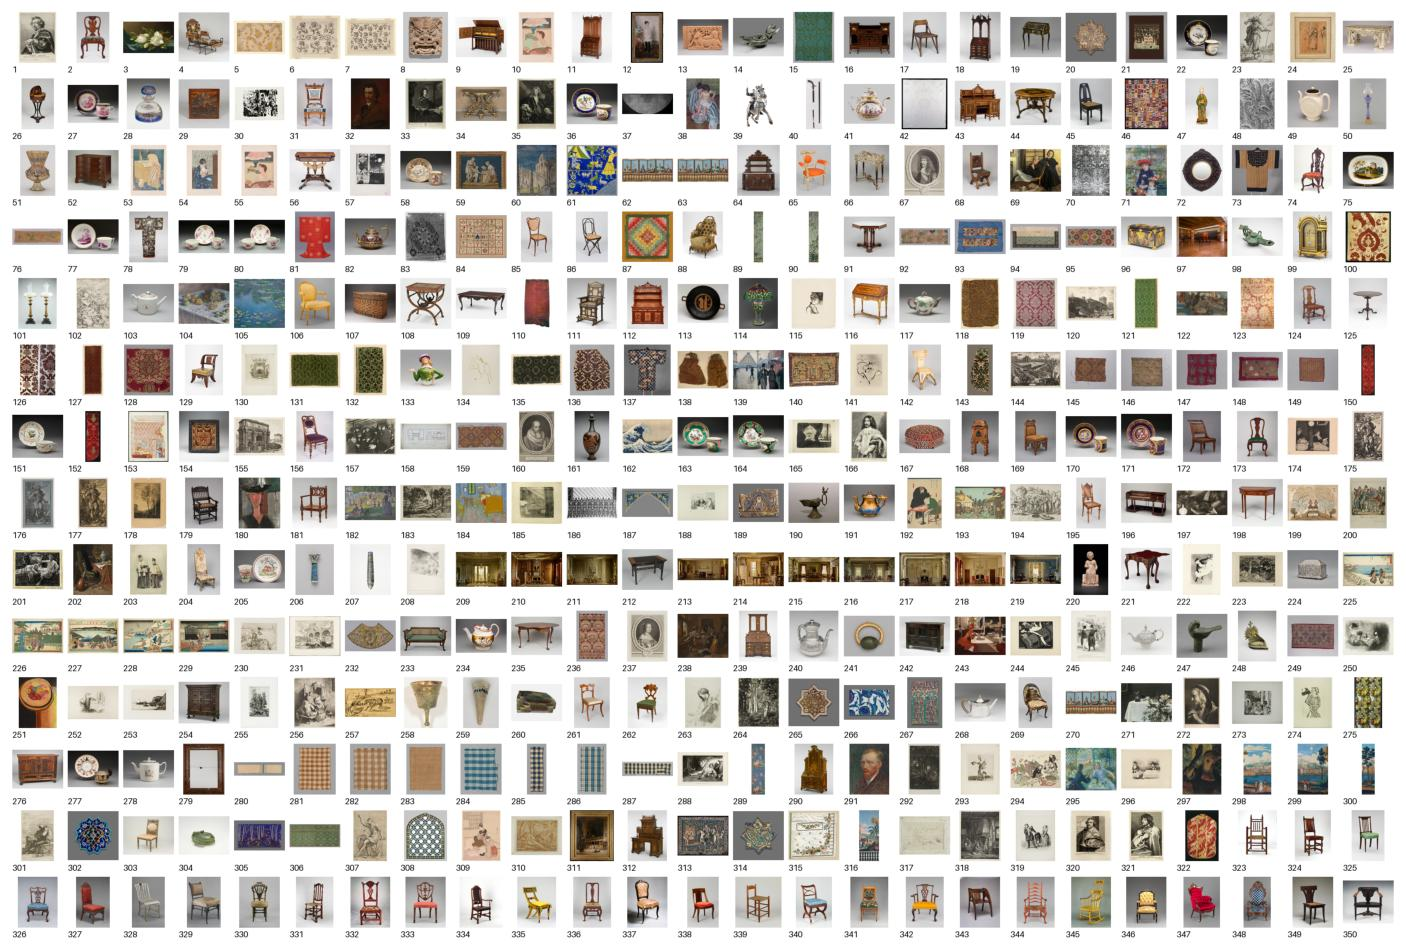

In [2]:
USE_EXAMPLE = True  # True: 350 museum images for the café chair. False: upload a zip of your own images.
BRIEF = "a new side chair for a museum café, inspired by historical chairs"  # change to your partner's brief
POOL_DIR = "pool"
os.makedirs(POOL_DIR, exist_ok=True)
credits = {}

def fetch(url, path):
    """Download url to path, unless it is already there from an earlier run."""
    if not os.path.exists(path):
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    return path

if USE_EXAMPLE:
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/"
    for folder, images in [("museum-chairs", "train"), ("mood-pool", "images")]:
        rows = list(csv.DictReader(open(fetch(f"{base}{folder}/credits.csv", f"credits-{folder}.csv"), encoding="utf-8")))
        credits.update({r["file"]: r for r in rows})
        with ThreadPoolExecutor(8) as ex:
            list(ex.map(lambda f: fetch(f"{base}{folder}/{images}/{f}", os.path.join(POOL_DIR, f)), [r["file"] for r in rows]))
    print("downloaded the example:", len(credits), "images")
else:
    from google.colab import files
    print("Pick a zip of your images:")
    for name, data in files.upload().items():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall(POOL_DIR)
        else:
            open(os.path.join(POOL_DIR, name), "wb").write(data)

EXT = (".jpg", ".jpeg", ".png", ".webp")
pool = sorted(p for p in glob.glob(os.path.join(POOL_DIR, "**", "*"), recursive=True)
              if p.lower().endswith(EXT) and "__MACOSX" not in p)
E = embed_images(pool)
print(len(pool), "images")
s = sheet(pool, cols=25, size=120, labels=range(1, len(pool) + 1))
s.save("pool.jpg", quality=85)
plt.figure(figsize=(18, 18 * s.height / s.width))
plt.imshow(s)
plt.axis("off")
plt.show()

## 3. Your board

Put the numbers (or file names) of 9 images in MY_BOARD. Pick them before you run the cells below, so the model's boards don't steer your choices. The example board has two café paintings, two pieces of checked cloth, a settee, a cup and saucer, a card table, a Thonet chair and a Shaker chair. Under the board, "How alike" is the average similarity between every pair of images on it, from 0 to 1. A lower number means a more varied board.

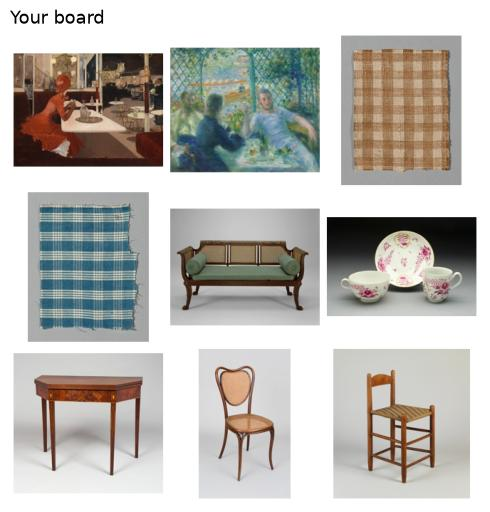

  243  In the Café, Fernand Lungren (American, 1857–1932), 1882–84
  295  Lunch at the Restaurant Fournaise (The Rowers' Lunch), Pierre-Auguste Renoir (French, 1841–1919), 1875
  282  Fragment, United States, early 19th century
  284  Fragment, United States, early 19th century
  233  Settee, Artist unknown (American, 18th–19th century), 1815–20
   80  Teacup, Coffee Cup, and Saucer, Worcester Porcelain Factory (Warmstry House Period, 1751–1783), c. 1770
  198  Card Table, Artist unknown (American, 18th century), c. 1790
   85  Side Chair, Designed by Michael Thonet; Austrian, 1796-1871; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1851; Manufactured c. 1855
  339  Side Chair, United Society of Believers in Christ’s Second Appearing (“Shakers”) (Maker), 1840–60
How alike: 0.69


In [3]:
# Pick 9 images for your board, by their numbers on the sheet above or by file name.
MY_BOARD = ["aic-59908.jpg", "aic-81555.jpg", "aic-79814.jpg", "aic-79819.jpg", "aic-52743.jpg",
            "aic-15079.jpg", "aic-3556.jpg", "aic-154050.jpg", "met-1866.jpg"]
names = [os.path.basename(p) for p in pool]
mine = [n if isinstance(n, int) else names.index(n) + 1 for n in MY_BOARD]
show_boards({"Your board": mine})
describe(mine)
print(f"How alike: {alike(mine):.2f}")

## 4. Search with the brief

This puts your brief through CLIP and picks the 9 images closest to it, which is what a plain search box does. In the example, all 9 are chairs and only 2 of them are on the hand-picked board. These 9 are also more alike than the hand-picked board (0.89 against 0.69).

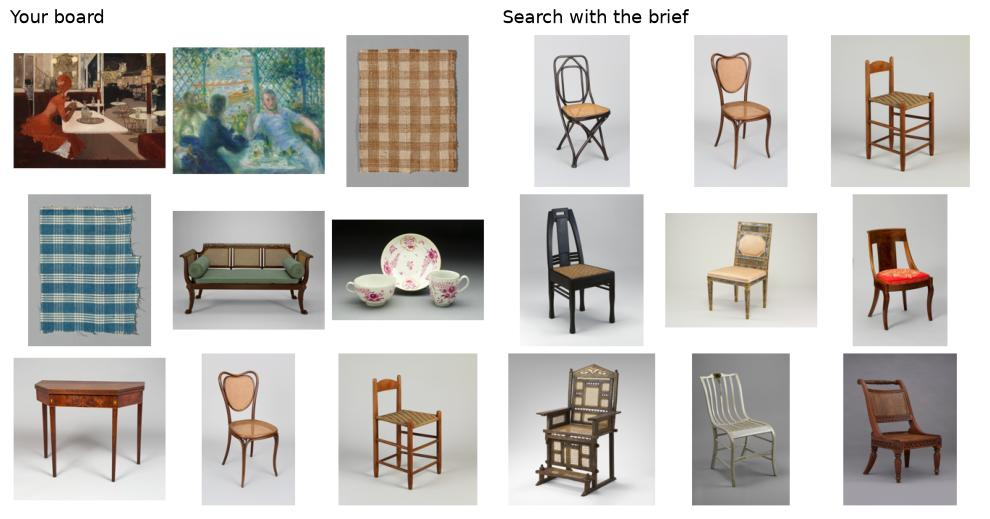

   86  Side Chair, Designed by August Thonet; Austrian, 1853-1921; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1885; Made c. 1900/15
   85  Side Chair, Designed by Michael Thonet; Austrian, 1796-1871; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1851; Manufactured c. 1855
  339  Side Chair, United Society of Believers in Christ’s Second Appearing (“Shakers”) (Maker), 1840–60
   45  Chair, Designed by Peter Behrens; German, 1868-1940; Germany, 1902
  303  Side Chair, Sicily, Italy, 1790/1800
  338  Side Chair, Attributed to Workshop of Duncan Phyfe (Maker); or attributed to Duncan Phyfe & Sons (Maker), ca. 1837
  111  Chair (Kiti Cha Enzi), Swahili; Lamu, Kenya; Eastern and Southern Africa, 19th century
  328  Side Chair, Samuel Gragg (Maker), ca. 1810
  172  Chair, West Indies or Asia (possibly Dutch-colonized Indonesia), c. 1820-40
How alike: your board 0.69, the search 0.89
2 of the 9 are on both boards


In [4]:
to_brief = E @ embed_texts([BRIEF])[0]
by_brief = [int(i) + 1 for i in np.argsort(-to_brief)[:9]]
show_boards({"Your board": mine, "Search with the brief": by_brief})
describe(by_brief)
print(f"How alike: your board {alike(mine):.2f}, the search {alike(by_brief):.2f}")
print(len(set(mine) & set(by_brief)), "of the 9 are on both boards")

## 5. More like these and surprise me

These are simple versions of two buttons in May AI, this week's first reading. May AI also learns from what you keep and remove as you work, and these do not. Set SEEDS to 3 images on your board (1 to 9, counting left to right and top to bottom). "More like these" picks the 9 images closest to those three. "Surprise me" first keeps the half of the images that are closest to the brief, and then picks the 9 from that half that are farthest from your three. In the example, the three are a café painting, a checked cloth and the Thonet chair. More like these comes back with 9 chairs, and surprise me with no chairs at all.

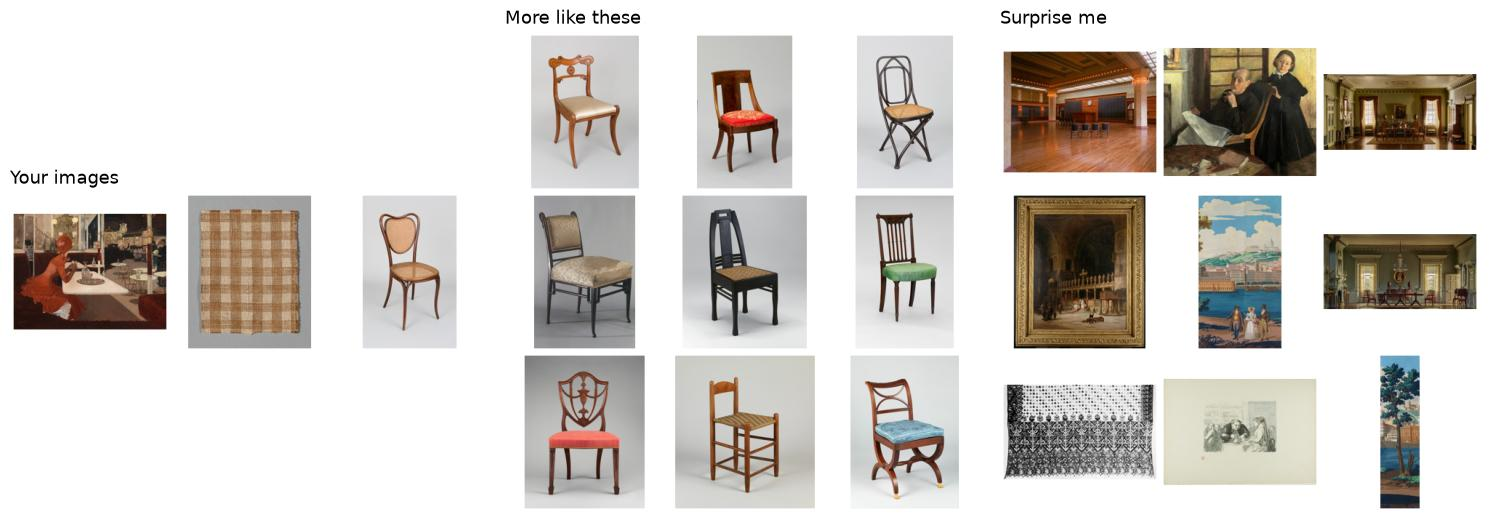

More like these: how alike 0.91, 1 also on your board
  261  Side Chair (one of two), England, c. 1820
  338  Side Chair, Attributed to Workshop of Duncan Phyfe (Maker); or attributed to Duncan Phyfe & Sons (Maker), ca. 1837
   86  Side Chair, Designed by August Thonet; Austrian, 1853-1921; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1885; Made c. 1900/15
  329  Chair, Attributed to Herter Brothers (Maker), ca. 1880
   45  Chair, Designed by Peter Behrens; German, 1868-1940; Germany, 1902
  325  Side chair, Possibly by William Worthington (Maker), 1805–15
  333  Side Chair, Attributed to Samuel McIntire (Maker), 1794–99
  339  Side Chair, United Society of Believers in Christ’s Second Appearing (“Shakers”) (Maker), 1840–60
  340  Side Chair, Attributed to Duncan Phyfe (Maker), 1791–1818
Surprise me: how alike 0.62, 0 also on your board
   97  Chicago Stock Exchange Trading Room: Reconstruction at the Art Institute of Chicago, Adler & Sullivan, original architects; America

In [5]:
SEEDS = [1, 3, 8]  # which images on your board to start from (1 to 9, left to right, top to bottom)
seeds = [mine[k - 1] for k in SEEDS]
to_seeds = (E @ E[[n - 1 for n in seeds]].T).mean(1)  # how close each image is to the ones you picked
rest = [n for n in range(1, len(pool) + 1) if n not in seeds]
more = sorted(rest, key=lambda n: -to_seeds[n - 1])[:9]
surprise = sorted([n for n in rest if to_brief[n - 1] >= np.median(to_brief)], key=lambda n: to_seeds[n - 1])[:9]
show_boards({"Your images": seeds, "More like these": more, "Surprise me": surprise})
for title, board in [("More like these", more), ("Surprise me", surprise)]:
    print(f"{title}: how alike {alike(board):.2f}, {len(set(mine) & set(board))} also on your board")
    describe(board)

## 6. Labels

SemanticCollage, this week's second reading, shows words under each image so that designers can say why they picked it. It gets its words from Google Cloud Vision. This cell does a small version with CLIP: it compares each image with the words in WORDS and shows the 5 closest. Add words that matter for your brief. In the example, the Renoir painting gets "dining", "painting", "conversation", "café" and "restaurant", and the Thonet chair gets "chair" and "rattan" but also "upholstery", which it does not have.

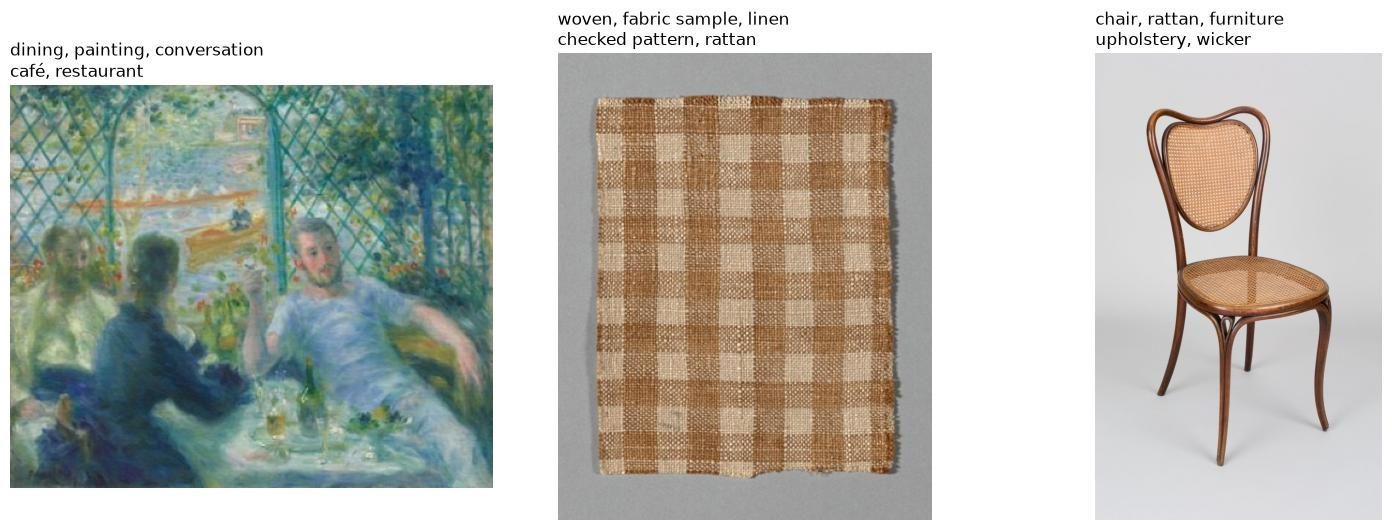

In [6]:
WORDS = ["wood", "oak", "walnut", "mahogany", "cane", "rattan", "wicker", "woven", "upholstery", "velvet", "damask", "leather", "linen", "cotton",
         "checked pattern", "stripes", "floral pattern", "geometric pattern", "porcelain", "glass", "brass", "iron", "marble", "lacquer",
         "café", "restaurant", "dining", "kitchen", "parlor", "garden", "street", "river", "people", "conversation", "lunch", "tea", "coffee",
         "warm", "cozy", "calm", "lively", "elegant", "rustic", "simple", "ornate", "light", "dark", "red", "blue", "green", "brown", "white",
         "gold", "painting", "print", "fabric sample", "furniture", "chair", "table", "teacup", "teapot", "lamp", "curves", "straight lines"]
LABEL = [2, 3, 8]  # which images on your board to label
W = embed_texts([f"a {w}" if w in ("painting", "print") else f"a photo of {w}" for w in WORDS])
fig, axes = plt.subplots(1, len(LABEL), figsize=(5 * len(LABEL), 5.4), squeeze=False)
for ax, k in zip(axes[0], LABEL):
    n = mine[k - 1]
    top = [WORDS[t] for t in np.argsort(-(E[n - 1] @ W.T))[:5]]
    ax.imshow(Image.open(pool[n - 1]).convert("RGB"))
    ax.set_title("\n".join([", ".join(top[:3]), ", ".join(top[3:])]), loc="left", fontsize=12)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Image and words

SemanticCollage also lets you search with an image and words together. This cell searches with one image from your board, first on its own and then with QUERY_WORDS added. In the example, the Thonet chair on its own finds 6 chairs, one of them with a cane seat. With "a chair with a woven cane seat" added, two cane chairs take the place of a chair with an upholstered seat and one with a leather seat.

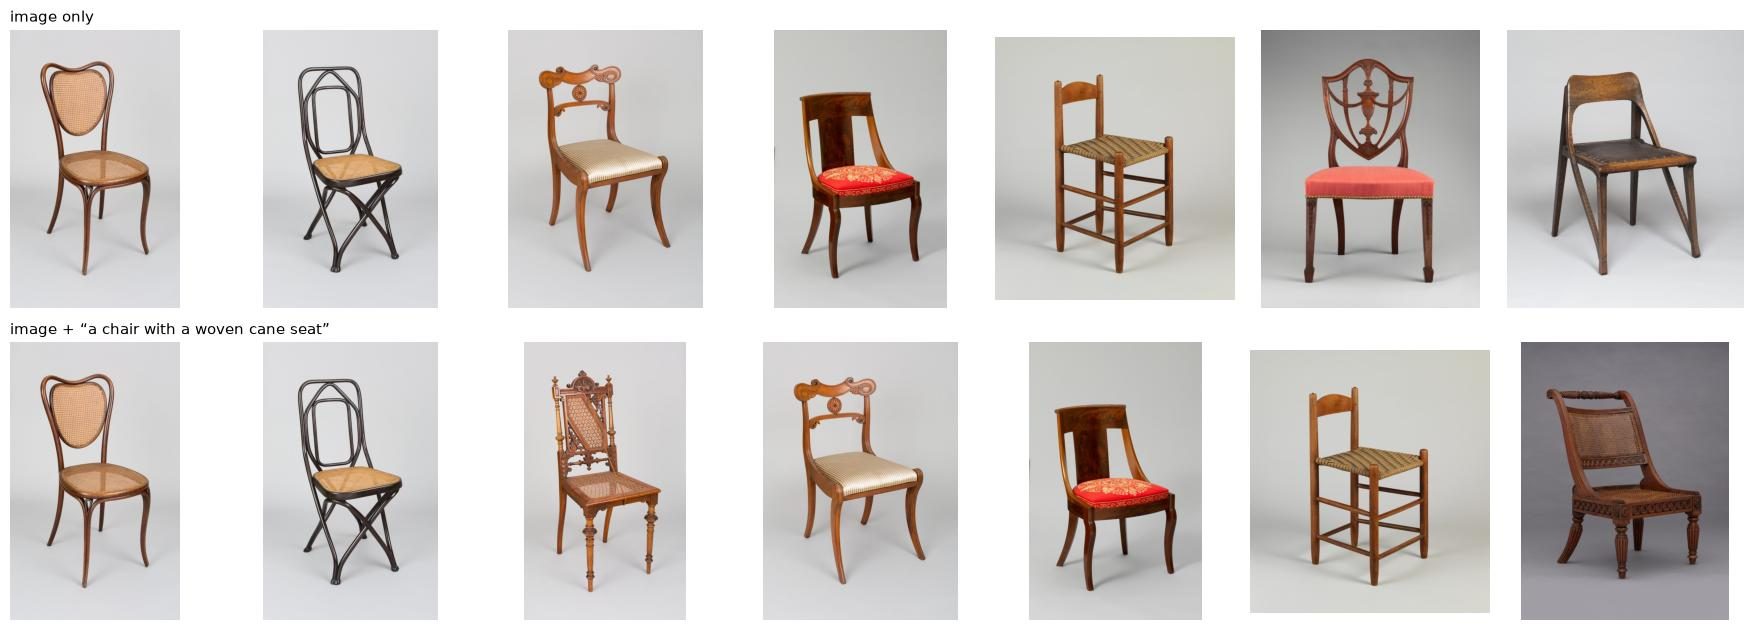

Image only:
   86  Side Chair, Designed by August Thonet; Austrian, 1853-1921; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1885; Made c. 1900/15
  261  Side Chair (one of two), England, c. 1820
  338  Side Chair, Attributed to Workshop of Duncan Phyfe (Maker); or attributed to Duncan Phyfe & Sons (Maker), ca. 1837
  339  Side Chair, United Society of Believers in Christ’s Second Appearing (“Shakers”) (Maker), 1840–60
  333  Side Chair, Attributed to Samuel McIntire (Maker), 1794–99
   17  Side Chair, Designed by Richard Riemerschmid; German, 1868-1957; Made by Vereinigte Werkstätten für Kunst und Handwerk; Munich, 1898/99
Image and words:
   86  Side Chair, Designed by August Thonet; Austrian, 1853-1921; Made by Gebrüder Thonet; Austrian, 1853-1921, Designed c. 1885; Made c. 1900/15
  195  Side Chair, Jacob Keller; German, active early 20th century; Gunzenhausen, Germany, 1900
  261  Side Chair (one of two), England, c. 1820
  338  Side Chair, Attributed to Workshop of Du

In [7]:
QUERY_IMAGE = 8  # an image on your board (1 to 9)
QUERY_WORDS = "a chair with a woven cane seat"
q = mine[QUERY_IMAGE - 1]
q_img = E[q - 1]
q_mix = q_img + embed_texts([QUERY_WORDS])[0]
q_mix = q_mix / np.linalg.norm(q_mix)
rest = [n for n in range(1, len(pool) + 1) if n != q]
image_only = sorted(rest, key=lambda n: -(E[n - 1] @ q_img))[:6]
image_words = sorted(rest, key=lambda n: -(E[n - 1] @ q_mix))[:6]
fig, axes = plt.subplots(2, 7, figsize=(18, 6.4))
for row, (title, found) in enumerate([("image only", image_only), (f"image + “{QUERY_WORDS}”", image_words)]):
    axes[row, 0].imshow(Image.open(pool[q - 1]).convert("RGB"))
    axes[row, 0].set_title(title, loc="left", fontsize=11)
    for k, n in enumerate(found):
        axes[row, k + 1].imshow(Image.open(pool[n - 1]).convert("RGB"))
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()
print("Image only:"); describe(image_only)
print("Image and words:"); describe(image_words)
print(len(set(image_only) & set(image_words)), "of the 6 are in both searches")

## 8. Your board and the model's board

Set MODEL_BOARD to the board you want to set next to yours: "brief", "more" or "surprise". It draws the two boards side by side and saves them as comparison.jpg, which you can download from the Files panel on the left. For the hand-in, add a few sentences on which board would help your partner's designers more with the brief, and why. For example, what does each board show about the material, the setting or the mood that the other one misses?

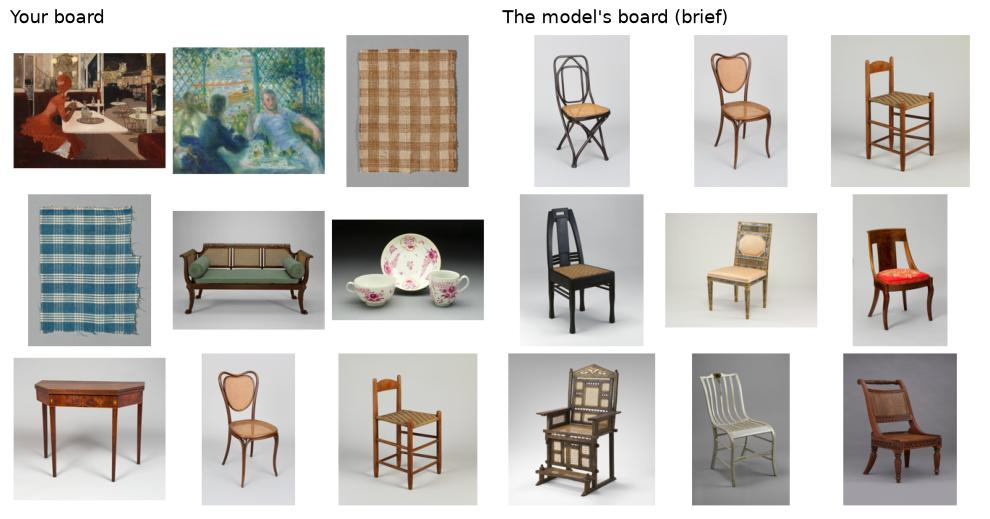

How alike: your board 0.69, the model's 0.89
2 of the 9 are on both boards. Saved comparison.jpg


In [8]:
MODEL_BOARD = "brief"  # "brief", "more" or "surprise": which of the model's boards to set next to yours
theirs = {"brief": by_brief, "more": more, "surprise": surprise}[MODEL_BOARD]
show_boards({"Your board": mine, f"The model's board ({MODEL_BOARD})": theirs}, save="comparison.jpg")
print(f"How alike: your board {alike(mine):.2f}, the model's {alike(theirs):.2f}")
print(len(set(mine) & set(theirs)), "of the 9 are on both boards. Saved comparison.jpg")